# Aviation Accidents Analysis

You are part of a consulting firm that is tasked to do an analysis of commercial and passenger jet airline safety. The client (an airline/airplane insurer) is interested in knowing what types of aircraft (makes/models) exhibit low rates of total destruction and low likelihood of fatal or serious passenger injuries in the event of an accident. They are also interested in any general variables/conditions that might be at play. Your analysis will be based off of aviation accident data accumulated from the years 1948-2023. 

Our client is only interested in airplane makes/models that are professional builds and could potentially still be active. Assume a max lifetime of 40 years for a make/model retirement and make sure to filter your data accordingly (i.e. from 1983 onwards). They would also like separate recommendations for small aircraft vs. larger passenger models. **In addition, make sure that claims that you make are statistically robust and that you have enough samples when making comparisons between groups.**


In this summative assessment you will demonstrate your ability to:
- Use Pandas to load, inspect, and clean the dataset appropriately. 
- Transform relevant columns to create measures that address the problem at hand.
- **conduct EDA: visualization and statistical measures to understand the structure of the data**
- **recommend a set of manufacturers to consider as well as specific airplanes conforming to the client's request**
- **discuss the relationship between serious injuries/airplane damage incurred and at least *two* factors at play in the incident. You must provide supporting evidence (visuals, summary statistics, tables) for each claim you make.**

In [1]:
# Load the libraries used in this notebook
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Exploratory Data Analysis  
- Load in the cleaned data

In [2]:
df = pd.read_csv("outputs/aviation_accidents_cleaned.csv", low_memory=False)
df["aircraft.destroyed"] = df["aircraft.destroyed"].map({"1": 1, "0": 0, 1: 1, 0: 0})
print(df.shape)
df.head()

(17879, 17)


,event.date,make,model,aircraft.type,total.fatal.injuries,total.serious.injuries,total.minor.injuries,total.uninjured,total_passengers,serious_injury_fatality_rate,aircraft.damage,aircraft.destroyed,weather.condition,engine.type,number.of.engines,purpose.of.flight,broad.phase.of.flight
0,1983-03-18,BOEING,747,BOEING_747,0.0,0.0,0.0,588.0,588.0,0.0,Minor,0.0,VMC,Turbo Fan,4.0,NaN,Taxi
1,1983-03-20,PIPER,PA-28-140,PIPER_PA-28-140,1.0,1.0,0.0,0.0,2.0,1.0,Destroyed,1.0,IMC,Reciprocating,1.0,Personal,Cruise
2,1983-04-02,DE HAVILLAND,DHC-6,DE HAVILLAND_DHC-6,1.0,0.0,0.0,4.0,5.0,0.2,NaN,NaN,VMC,Turbo Prop,2.0,Skydiving,Standing
3,1983-11-08,BOEING,727-200,BOEING_727-200,0.0,0.0,0.0,100.0,100.0,0.0,Minor,0.0,VMC,Turbo Fan,3.0,NaN,Taxi
4,1983-11-13,BEECH,C35,BEECH_C35,0.0,0.0,0.0,1.0,1.0,0.0,Substantial,0.0,VMC,Reciprocating,1.0,Personal,Climb


## Explore safety metrics across models/makes
- Remember that the client is interested in separate recommendations for smaller airplanes and larger airplanes. Choose a passenger threshold of 20 and separate the plane types. 

In [3]:
# Separate smaller and larger planes using the threshold from the assignment.
df["plane.size"] = "Small"
df.loc[df["total_passengers"] > 20, "plane.size"] = "Large"
df = df[df["total_passengers"] > 0]
df.groupby("plane.size")["serious_injury_fatality_rate"].agg(["count", "mean", "median"])

,count,mean,median
plane.size,,,
Large,873,0.059135,0.0
Small,16230,0.286856,0.0


#### Analyzing Makes

Explore the human injury risk profile for small and larger Makes:
- choose the 15 makes for each group possessing the lowest mean fatal/seriously injured fraction
- plot the mean fatal/seriously injured fraction for each of these subgroups side-by-side

,make,mean,count
13,BOMBARDIER INC,0.090909,11
27,MCDONNELL DOUGLAS,0.094048,30
12,BOMBARDIER,0.103846,15
11,BOEING,0.141973,272
7,AVIAT AIRCRAFT INC,0.164474,76
26,MAULE,0.164806,215
24,GRUMMAN ACFT ENG COR-SCHWEIZER,0.206897,58
8,AYRES,0.215686,51
34,STINSON,0.216408,129
6,AVIAT,0.221429,70


,make,mean,count
10,MCDONNELL DOUGLAS,0.007827,53
4,BOMBARDIER INC,0.028690,43
2,BOEING,0.056771,547
3,BOMBARDIER,0.063701,21
8,EMBRAER,0.065274,78
0,AIRBUS,0.086249,118


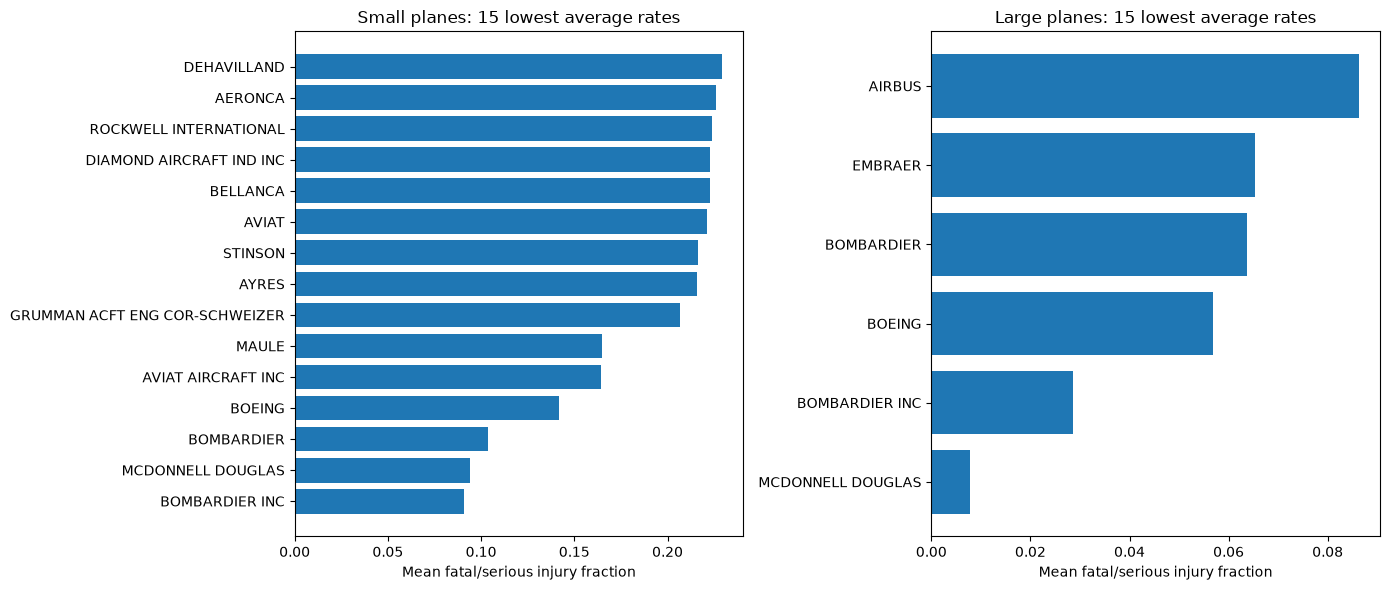

In [4]:
# Average injury rate by make for small planes. Keep makes with at least 10 records.
small_planes = df[df["plane.size"] == "Small"]
small_make_summary = small_planes.groupby("make")["serious_injury_fatality_rate"].agg(["mean", "count"]).reset_index()
small_make_summary = small_make_summary[small_make_summary["count"] >= 10]
small_15 = small_make_summary.sort_values("mean").head(15)

# Do the same for large planes.
large_planes = df[df["plane.size"] == "Large"]
large_make_summary = large_planes.groupby("make")["serious_injury_fatality_rate"].agg(["mean", "count"]).reset_index()
large_make_summary = large_make_summary[large_make_summary["count"] >= 10]
large_15 = large_make_summary.sort_values("mean").head(15)
display(small_15)
display(large_15)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
axes[0].barh(small_15["make"], small_15["mean"])
axes[0].set_title("Small planes: 15 lowest average rates")
axes[0].set_xlabel("Mean fatal/serious injury fraction")
axes[1].barh(large_15["make"], large_15["mean"])
axes[1].set_title("Large planes: 15 lowest average rates")
axes[1].set_xlabel("Mean fatal/serious injury fraction")
plt.tight_layout()

**Distribution of injury rates: small makes**

Use a violinplot to look at the distribution of the fraction of passengers serious/fatally injured for small airplane makes. Just display makes with the ten lowest mean serious/fatal injury rates.

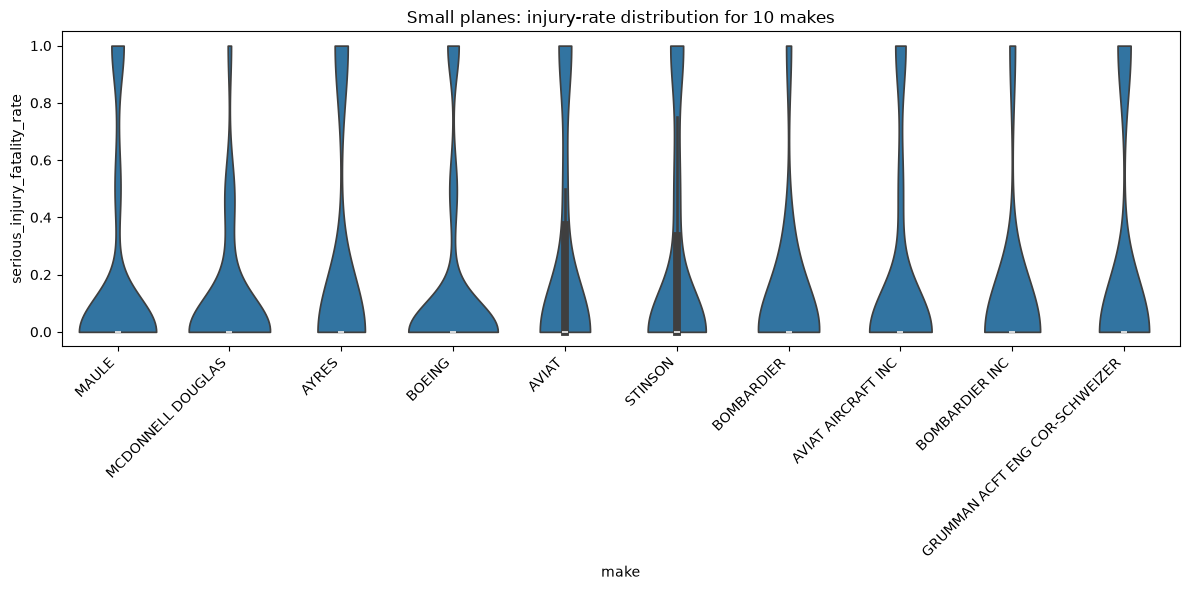

In [5]:
# Show distributions for the 10 small-plane makes with the lowest averages.
small_10_names = small_15.head(10)["make"].tolist()
small_10_data = small_planes[small_planes["make"].isin(small_10_names)]
plt.figure(figsize=(12, 6))
sns.violinplot(data=small_10_data, x="make", y="serious_injury_fatality_rate", cut=0)
plt.xticks(rotation=45, ha="right")
plt.title("Small planes: injury-rate distribution for 10 makes")
plt.tight_layout()

**Distribution of injury rates: large makes**

Use a stripplot to look at the distribution of the fraction of passengers serious/fatally injured for large airplane makes. Just display makes with the ten lowest mean serious/fatal injury rates.

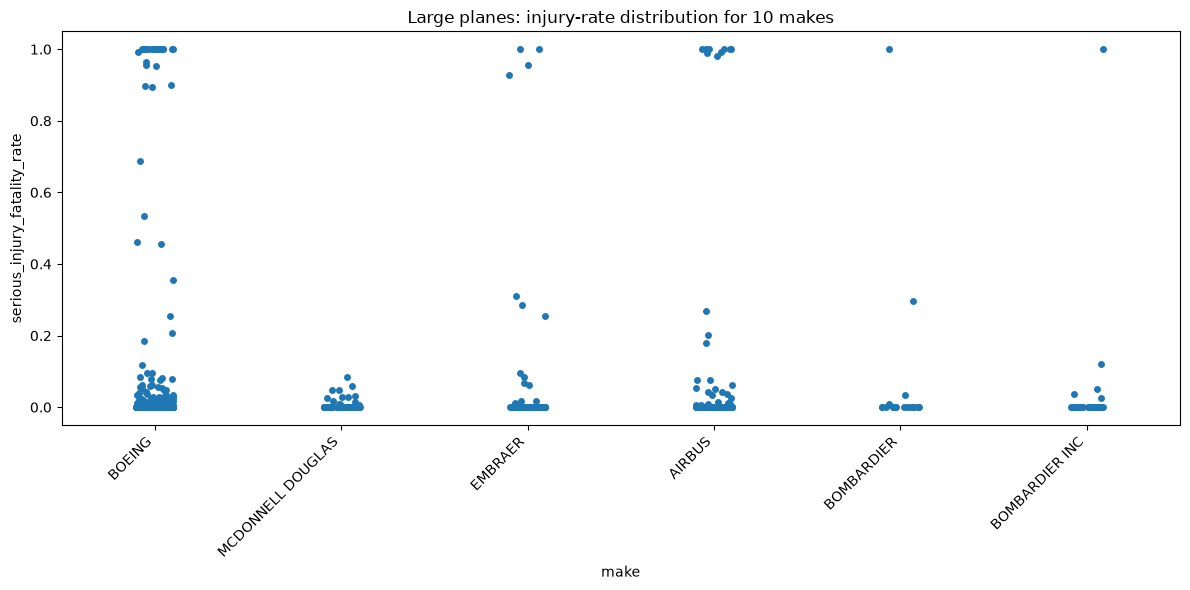

In [6]:
# Show distributions for the 10 large-plane makes with the lowest averages.
large_10_names = large_15.head(10)["make"].tolist()
large_10_data = large_planes[large_planes["make"].isin(large_10_names)]
plt.figure(figsize=(12, 6))
sns.stripplot(data=large_10_data, x="make", y="serious_injury_fatality_rate", jitter=True)
plt.xticks(rotation=45, ha="right")
plt.title("Large planes: injury-rate distribution for 10 makes")
plt.tight_layout()

**Evaluate the rate of aircraft destruction for both small and large aircraft by Make.** 

Sort your results and keep the lowest 15.

In [7]:
# The mean of a 1/0 column is the fraction destroyed.
small_damage = small_planes.groupby("make")["aircraft.destroyed"].agg(["mean", "count"]).reset_index()
small_damage = small_damage[small_damage["count"] >= 10].sort_values("mean").head(15)
large_damage = large_planes.groupby("make")["aircraft.destroyed"].agg(["mean", "count"]).reset_index()
large_damage = large_damage[large_damage["count"] >= 10].sort_values("mean").head(15)
display(small_damage)
display(large_damage)

,make,mean,count
25,LUSCOMBE,0.014493,138
24,GRUMMAN ACFT ENG COR-SCHWEIZER,0.017241,58
34,STINSON,0.023256,129
35,TAYLORCRAFT,0.032258,93
1,AERONCA,0.035000,200
22,ERCOUPE,0.038462,52
5,AMERICAN CHAMPION AIRCRAFT,0.039216,51
7,AVIAT AIRCRAFT INC,0.040000,75
26,MAULE,0.041860,215
19,DEHAVILLAND,0.044444,90


,make,mean,count
4,BOMBARDIER INC,0.038462,26
3,BOMBARDIER,0.055556,18
8,EMBRAER,0.088889,45
2,BOEING,0.096774,279
10,MCDONNELL DOUGLAS,0.111111,36
0,AIRBUS,0.169811,53


#### Provide a short discussion on your findings for your summary statistics and plots:
- Make any recommendations for Makes here based off of the destroyed fraction and fraction fatally/seriously injured
- Comment on the calculated statistics and any corresponding distributions you have visualized.

### What the make summaries show

Among small-plane accident records, Bombardier Inc. has the lowest average fatal/serious injury fraction in the make table (about 9.1%, 11 records), followed by McDonnell Douglas (9.4%, 30 records). Luscombe has the lowest observed small-plane destruction fraction (1.4%, 138 records with known damage). These are different makes, so injury and aircraft destruction should be considered separately.

For large-plane accident records, McDonnell Douglas has the lowest average injury fraction (0.8%, 53 records), while Bombardier Inc. has the lowest destruction fraction (3.8%, 26 records with known damage). The large-plane groups are much smaller than many small-plane groups. The violin and strip plots also show that individual accident rates vary, even for makes with low averages.

These are possible makes for further review, not proof that one make is safer. Each number describes only the accidents in this dataset.

### Analyze plane types
- plot the mean fatal/seriously injured fraction for both small and larger planes 
- also provide a distributional plot of your choice for the fatal/seriously injured fraction by airplane type (stripplot, violin, etc)  
- filter ensuring that you have at least ten individual examples in each model/make to average over

**Larger planes**

,make,model,aircraft.type,mean,count
148,BOEING,777,BOEING_777,0.000821,33
113,BOEING,757,BOEING_757,0.001473,18
164,BOEING,787,BOEING_787,0.003058,11
86,BOEING,737-7H4,BOEING_737-7H4,0.003242,12
205,BOMBARDIER INC,CL-600-2B19,BOMBARDIER INC_CL-600-2B19,0.004431,14
244,EMBRAER,EMB145,EMBRAER_EMB145,0.008798,11
239,EMBRAER,EMB-145LR,EMBRAER_EMB-145LR,0.010000,15
101,BOEING,747,BOEING_747,0.023161,11
127,BOEING,767,BOEING_767,0.046963,31
64,BOEING,737 7H4,BOEING_737 7H4,0.068121,14


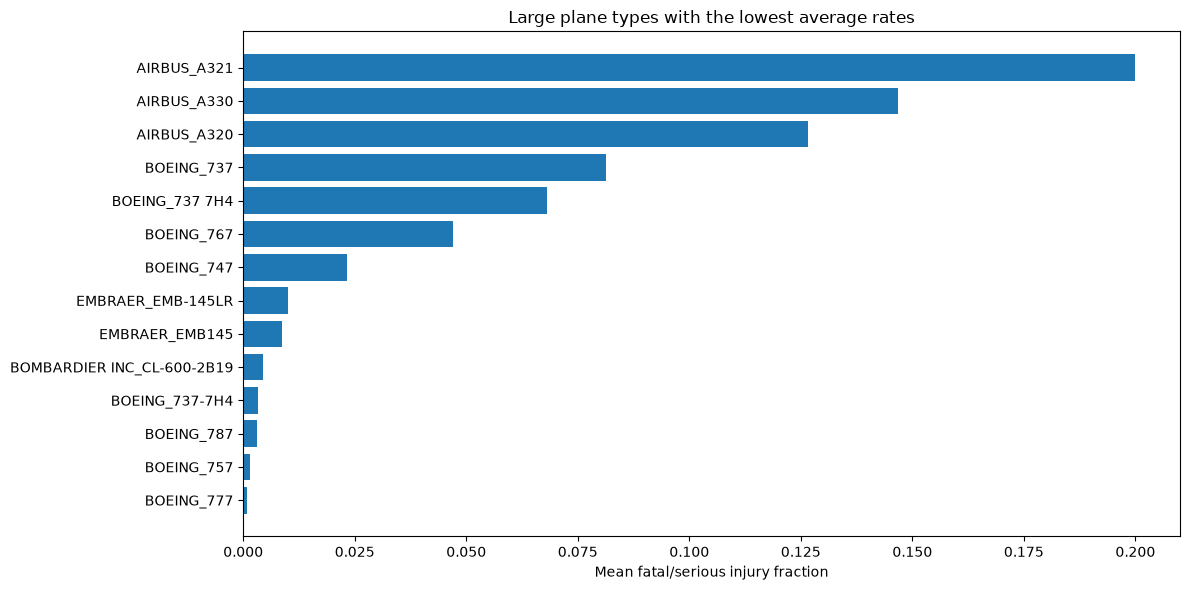

In [8]:
# Average injury fraction by make and model for large planes.
large_type_summary = large_planes.groupby(["make", "model", "aircraft.type"])["serious_injury_fatality_rate"].agg(["mean", "count"]).reset_index()
large_type_summary = large_type_summary[large_type_summary["count"] >= 10]
large_type_summary = large_type_summary.sort_values("mean").head(15)
display(large_type_summary)
plt.figure(figsize=(12, 6))
plt.barh(large_type_summary["aircraft.type"], large_type_summary["mean"])
plt.xlabel("Mean fatal/serious injury fraction")
plt.title("Large plane types with the lowest average rates")
plt.tight_layout()

**Smaller planes**
- for smaller planes, limit your plotted results to the makes with the 10 lowest mean serious/fatal injury fractions

,make,model,aircraft.type,mean,count
196,MAULE,M-5-210C,MAULE_M-5-210C,0.000000,11
79,BOEING,747,BOEING_747,0.076923,26
64,BOEING,737,BOEING_737,0.083333,36
265,STINSON,108-1,STINSON_108-1,0.083333,16
237,MAULE,MX7,MAULE_MX7,0.125000,18
123,BOEING,A75N1(PT17),BOEING_A75N1(PT17),0.139785,31
3,AVIAT,A-1B,AVIAT_A-1B,0.142857,21
29,AVIAT AIRCRAFT INC,A-1B,AVIAT AIRCRAFT INC_A-1B,0.181818,22
120,BOEING,A75N1,BOEING_A75N1,0.187500,16
211,MAULE,M5,MAULE_M5,0.192308,13


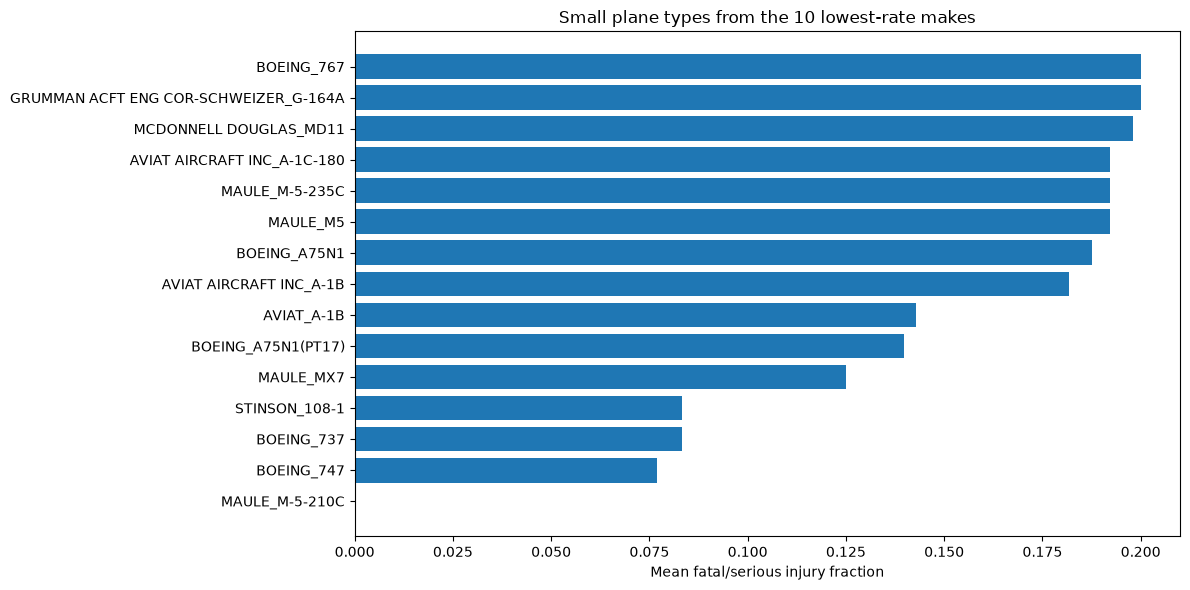

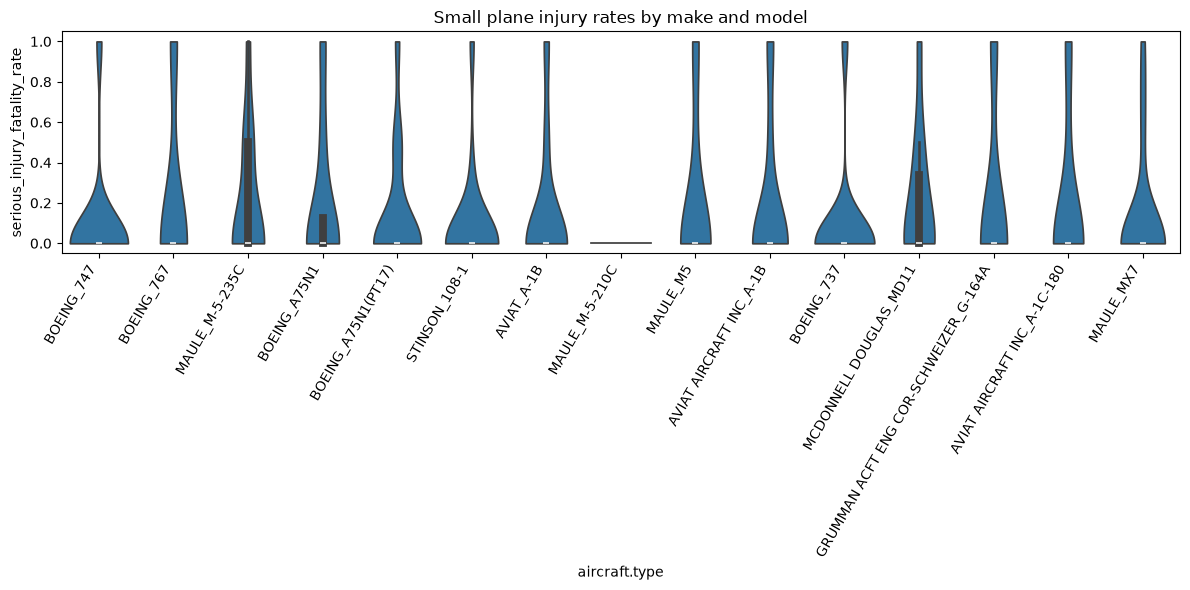

In [9]:
# For small planes, keep makes with the 10 lowest averages, then compare models.
small_10_names = small_15.head(10)["make"].tolist()
small_10_planes = small_planes[small_planes["make"].isin(small_10_names)]
small_type_summary = small_10_planes.groupby(["make", "model", "aircraft.type"])["serious_injury_fatality_rate"].agg(["mean", "count"]).reset_index()
small_type_summary = small_type_summary[small_type_summary["count"] >= 10]
small_type_summary = small_type_summary.sort_values("mean").head(15)
display(small_type_summary)
plt.figure(figsize=(12, 6))
plt.barh(small_type_summary["aircraft.type"], small_type_summary["mean"])
plt.xlabel("Mean fatal/serious injury fraction")
plt.title("Small plane types from the 10 lowest-rate makes")
plt.tight_layout()
small_type_data = small_10_planes[small_10_planes["aircraft.type"].isin(small_type_summary["aircraft.type"])]
plt.figure(figsize=(12, 6))
sns.violinplot(data=small_type_data, x="aircraft.type", y="serious_injury_fatality_rate", cut=0)
plt.xticks(rotation=60, ha="right")
plt.title("Small plane injury rates by make and model")
plt.tight_layout()

### Discussion of Specific Airplane Types
- Discuss what you have found above regarding passenger fraction seriously/ both small and large airplane models.

### Discussion of plane types

Among the large-plane types with at least 10 accident records, Boeing 777 has the lowest average injury fraction in this dataset (about 0.08%, 33 records), followed by Boeing 757 (about 0.15%, 18 records). For the small-plane grouping, Maule M-5-210C has an average of zero fatal/serious injuries in 11 records. These small samples make the rankings uncertain, and other types have higher averages and wider distributions.

The assignment divides aircraft using the number of people reported on board. As a result, a model normally thought of as large can appear in the small group when an accident report lists 20 or fewer people. Treat these results as comparisons by reported occupancy, not as a complete measure of aircraft size.

### Exploring Other Variables
- Investigate how other variables effect aircraft damage and injury. You must choose **two** factors out of the following but are free to analyze more:

- Weather Condition
- Engine Type
- Number of Engines
- Phase of Flight
- Purpose of Flight

For each factor provide a discussion explaining your analysis with appropriate visualization / data summaries and interpreting your findings.

### Weather condition

In the records with a known weather category, the mean injury fraction is higher for IMC (about 62.8%, 895 records) than for VMC (about 23.3%, 14,248 records). The destruction fractions are about 37.0% for IMC and 7.2% for VMC. This shows an association in the accident records; it does not show that weather alone caused the difference.

### Engine type

Turbo Fan accident records have a lower average injury fraction (about 9.0%, 589 records) than Reciprocating (25.4%, 12,814), Turbo Jet (19.5%, 66), and Turbo Prop (32.1%, 918) records. Destruction fractions are about 9.7%, 7.9%, 25.6%, and 19.0%, respectively. Engine types are used in different kinds of aircraft and missions, so these averages should not be used to claim that one engine type causes safer outcomes. The very small Geared Turbofan and Turbo Shaft groups are too small to compare reliably.

,weather.condition,mean,count
1,VMC,0.233090,14248
0,IMC,0.628008,895


,weather.condition,aircraft.destroyed
0,IMC,0.370153
1,VMC,0.072498


,engine.type,mean,count
0,Geared Turbofan,0.000000,1
2,Turbo Fan,0.089963,589
5,Turbo Shaft,0.111111,9
3,Turbo Jet,0.195023,66
1,Reciprocating,0.254148,12814
4,Turbo Prop,0.320931,918


,engine.type,aircraft.destroyed
0,Geared Turbofan,0.000000
1,Reciprocating,0.078776
2,Turbo Fan,0.097222
3,Turbo Jet,0.255814
4,Turbo Prop,0.189675
5,Turbo Shaft,0.000000


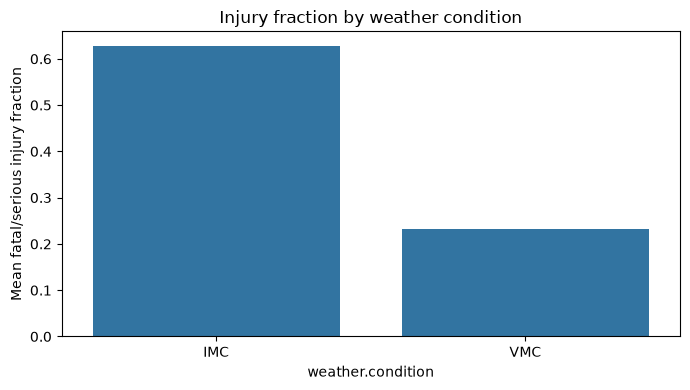

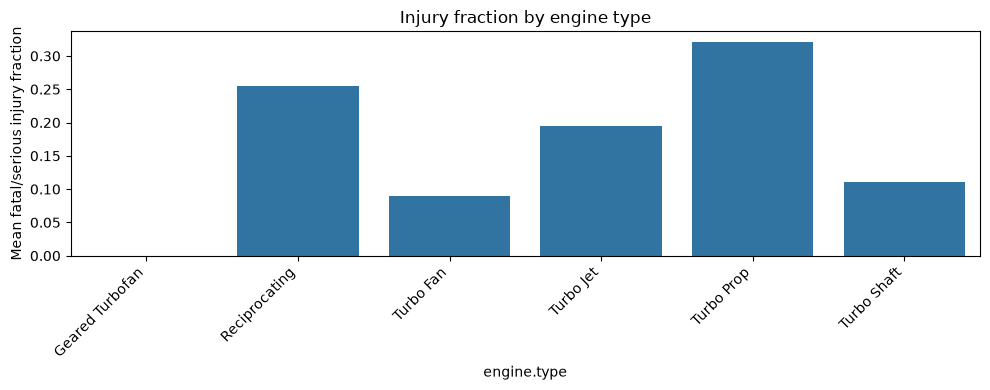

In [10]:
# Compare average injury and destruction rates by weather.
weather_injury = df.groupby("weather.condition")["serious_injury_fatality_rate"].agg(["mean", "count"]).reset_index()
weather_damage = df.groupby("weather.condition")["aircraft.destroyed"].mean().reset_index()
display(weather_injury.sort_values("mean"))
display(weather_damage)
plt.figure(figsize=(7, 4))
sns.barplot(data=weather_injury, x="weather.condition", y="mean")
plt.ylabel("Mean fatal/serious injury fraction")
plt.title("Injury fraction by weather condition")
plt.tight_layout()

# Compare averages by engine type.
engine_injury = df.groupby("engine.type")["serious_injury_fatality_rate"].agg(["mean", "count"]).reset_index()
engine_damage = df.groupby("engine.type")["aircraft.destroyed"].mean().reset_index()
display(engine_injury.sort_values("mean"))
display(engine_damage)
plt.figure(figsize=(10, 4))
sns.barplot(data=engine_injury, x="engine.type", y="mean")
plt.xticks(rotation=45, ha="right")
plt.ylabel("Mean fatal/serious injury fraction")
plt.title("Injury fraction by engine type")
plt.tight_layout()

### Overall limitation

All summaries in this notebook are based on reported accident cases. We do not have the total number of flights or flight hours for each make, model, weather condition, or engine type. Therefore, this analysis compares outcomes after an accident and cannot estimate the chance of an accident during normal operation.